# Exploring the K10plus Biblical Studies harvest

Opening cells for the Parquet files produced by `biblical-books harvest` + `biblical-books export`.

**Read this before drawing conclusions from any number below.**

- `records.parquet` is the union of the nine configured searches (DDC `22*`, LCC `BS*`, four subject
  searches, three title supplements), deduplicated by K10plus record ID. It is a set of **candidates**.
- `books.parquet` is a **format filter** on that set: MARC leader type `a` + bibliographic level `m`
  (textual monographs, edited volumes included). It still contains primary texts, devotional works and
  false positives. It is *not* a validated academic corpus.
- Coverage of K10plus is incomplete, so "the configured union" is not "all Biblical Studies books".
- The catalogue is live and was paged by offset; counts can drift while harvesting. `export.json`
  records `selection_complete`; a partial export is marked as such and may be used for inspection only.
- Print/e-book editions, translations and revised editions are separate rows. Nothing is collapsed at
  work level here.

Analysis conventions used below: `publication_year` comes from MARC 008 date1 when numeric, otherwise
from a single unambiguous year in 260/264 $c; `date_type` says what date1 means (reprint, multipart,
forthcoming…). Unknown stays null — never impute it.

## 1. Manifests: what was exported, and was the harvest complete?

`export.json` is written by `biblical-books export`; it repeats the `status` report so a figure can
always be traced to a known retrieval date and completion state.

In [1]:
import json
from pathlib import Path

import pandas as pd

# This notebook lives in scripts/, but the harvest writes to data/k10plus/ at the repository
# root. Walk up from the working directory so the notebook runs from either folder.
DATA_DIR = next(
    (
        folder / "data/k10plus"
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data" / "k10plus" / "export.json").exists()
    ),
    None,
)
assert DATA_DIR is not None, "data/k10plus/export.json not found above the working directory"
print("DATA_DIR:", DATA_DIR)

manifest = json.loads((DATA_DIR / "export.json").read_text())
print("exported_at       :", manifest["exported_at"])
print("selection_complete:", manifest["status"]["selection_complete"])
print("records           :", manifest["records"])
print("textual monographs:", manifest["textual_monographs"])

per_query = pd.DataFrame(manifest["status"]["queries"])
per_query[["id", "cql", "pages", "downloaded_occurrences", "advertised_total", "complete"]]

DATA_DIR: /home/jupyter-vojta/notebooks/biblical-books/data/k10plus
exported_at       : 2026-11-20T15:36:28.953813+00:00
selection_complete: True
records           : 525205
textual monographs: 300542


,id,cql,pages,downloaded_occurrences,advertised_total,complete
0,ddc_bible,pica.ddc=22*,776,77511,77511,True
1,lcc_bible,pica.lcc=BS*,561,56071,56071,True
2,subject_bibel,pica.sw=Bibel,3592,359129,359129,True
3,subject_bible,pica.lsh=Bible,890,88996,88996,True
4,subject_new_testament,"pica.sw=""Neues Testament""",783,78296,78296,True
5,subject_old_testament,"pica.sw=""Altes Testament""",873,87288,87288,True
6,title_biblical,pica.tit=biblical,454,45393,45393,True
7,title_biblique,pica.tit=biblique*,69,6883,6883,True
8,title_biblisch,pica.tit=biblisch*,566,56568,56568,True


## 2. Load the tables

Load **only the columns you need**: `marc_json` dominates memory (the whole MARC record as JSON per row).
Both files are streamed into Parquet in bounded row groups, so reading a column subset is cheap.

In [2]:
COLUMNS = [
    "record_id", "full_title", "publication_year", "date_type", "languages",
    "record_type", "bibliographic_level", "is_textual_monograph", "matched_queries",
]

books = pd.read_parquet(DATA_DIR / "books.parquet", columns=COLUMNS, dtype_backend="pyarrow")
candidates = pd.read_parquet(
    DATA_DIR / "records.parquet",
    columns=["record_id", "is_textual_monograph", "matched_queries"],
    dtype_backend="pyarrow",
)

assert books.record_id.is_unique, "record_id must be unique"
assert candidates.record_id.is_unique, "record_id must be unique"
assert len(books) == manifest["textual_monographs"], "row count disagrees with export.json"
assert len(candidates) == manifest["records"], "row count disagrees with export.json"

print(f"candidates: {len(candidates):,}   textual monographs: {len(books):,}")
print(f"monograph share: {len(books) / len(candidates):.1%}")
books.head(5)

candidates: 525,205   textual monographs: 300,542
monograph share: 57.2%


,record_id,full_title,publication_year,date_type,languages,record_type,bibliographic_level,is_textual_monograph,matched_queries
0,010017054,Du gibst weiten Raum meinen Schritten: Lebensm...,1980,s,['ger'],a,m,True,['subject_bibel']
1,010021817,Mittelpunkt Bibel: Ulrich Fick zum 60. Geburtstag,1983,s,['ger' 'eng'],a,m,True,['ddc_bible' 'subject_bibel']
2,01002235X,Grammatik des Biblisch-Aramäischen,1981,s,['und'],a,m,True,['title_biblisch']
3,010022643,Die Bibel oder die ganze heilige Schrift des A...,1982,s,['ger'],a,m,True,['subject_bibel']
4,010037403,Frauenbefreiung: biblische und theologische Ar...,1986,s,['ger'],a,m,True,['title_biblisch']


## 3. Which search found what?

Advertised counts overlap heavily, so the useful question is not "how many per query" but
**"how many records would be lost if this query were dropped"** — i.e. records matched by that query
and nothing else.

In [3]:
long = candidates[["record_id", "matched_queries"]].explode("matched_queries")
long = long.rename(columns={"matched_queries": "query"})

hits = long.groupby("query").size().rename("records_matched")
exclusive = (
    candidates.assign(n=candidates.matched_queries.list.len())
    .query("n == 1")
    .matched_queries.explode()
    .value_counts()
    .rename("only_source_for")
)
contribution = pd.concat([hits, exclusive], axis=1).fillna(0).astype(int)
contribution["share_of_candidates"] = contribution.records_matched / len(candidates)
contribution.sort_values("only_source_for", ascending=False)

,records_matched,only_source_for,share_of_candidates
subject_bibel,359127,168316,0.683784
title_biblisch,56567,45373,0.107705
subject_bible,88996,35366,0.169450
title_biblical,45393,30092,0.086429
ddc_bible,77511,13338,0.147582
title_biblique,6883,4909,0.013105
lcc_bible,56071,3679,0.106760
subject_old_testament,87288,187,0.166198
subject_new_testament,78296,73,0.149077


## 4. Publication years

Missing years are reported, not filled. `date_type` (MARC 008/06) explains what date1 means:
`s` single known date, `m` multiple dates (multipart), `r` reprint, `t` publication + copyright.
Forthcoming years are legitimate values.

In [4]:
years = books.publication_year.dropna().astype("int64")
print(f"known year: {len(years):,} of {len(books):,} ({len(years) / len(books):.1%})")
print("range     :", years.min(), "-", years.max())
print()
print("date_type:")
print(books.date_type.value_counts(dropna=False).head(8).to_string())
print()

decade = (years // 10 * 10).value_counts().sort_index()
decade[decade.index >= 1800]

known year: 295,261 of 300,542 (98.2%)
range     : 0 - 2027

date_type:
date_type
s    284294
m      8257
n      5237
r      2753
g         1



publication_year
1800     1768
1810     2237
1820     2285
1830     3009
1840     3292
1850     3935
1860     4215
1870     4219
1880     5273
1890     6915
1900     8397
1910     7359
1920     7234
1930     6497
1940     3870
1950     7497
1960    12036
1970    14618
1980    19376
1990    25796
2000    28867
2010    37080
2020    21850
Name: count, dtype: int64

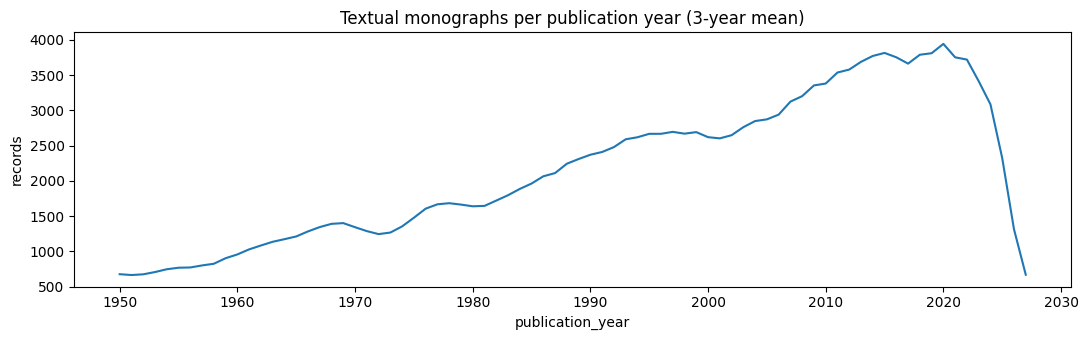

In [5]:
# Optional plot; matplotlib is a notebook-only dependency, not part of the project.
try:
    import matplotlib.pyplot as plt
except ImportError:
    print("matplotlib not installed - skipping plot")
else:
    yearly = years[(years >= 1950) & (years <= years.max())].value_counts().sort_index()
    ax = yearly.rolling(3, center=True, min_periods=1).mean().plot(
        figsize=(11, 3.5), title="Textual monographs per publication year (3-year mean)"
    )
    ax.set_xlabel("publication_year")
    ax.set_ylabel("records")
    plt.tight_layout()

## 5. Languages

Codes are preserved as catalogued (MARC 041 $a plus 008/35-37), never translated, and never normalised
across `eng`/`en`, `ger`/`deu`, `fre`/`fra` — that harmonisation belongs in the analysis, explicitly.

In [6]:
langs = books.languages.explode().dropna()
n_lang = books.languages.list.len().fillna(0).astype("int64")

print(f"records with no language code: {(n_lang == 0).sum():,} ({(n_lang == 0).mean():.1%})")
print(f"records with >1 language    : {(n_lang > 1).sum():,}")
print()
langs.value_counts().head(15)

records with no language code: 0 (0.0%)
records with >1 language    : 18,090



languages
eng    115484
ger    113289
und     23090
lat     22240
fre     12737
heb      7736
ita      5723
grc      4542
spa      3112
dut      2204
ara      1444
gre       828
rus       632
arc       588
pol       488
Name: count, dtype: int64[pyarrow]

## 6. Missingness of the key metadata

Cataloguing depth varies by record; a low fill rate is a statement about K10plus editing, not about the
books. `is_textual_monograph` and `leader` are always present by construction.

In [7]:
CHECK = [
    "title", "subtitle", "responsibility", "publication_year", "date_text",
    "publishers", "publication_places", "isbns", "languages", "subjects",
    "series", "ddc", "lcc", "abstract", "urls",
]
probe = pd.read_parquet(DATA_DIR / "books.parquet", columns=CHECK, dtype_backend="pyarrow")

def filled(series):
    """True when a scalar is non-null/non-empty, or a list column has at least one element."""
    if isinstance(series.dtype, pd.ArrowDtype) and str(series.dtype).startswith("list"):
        return series.list.len().fillna(0) > 0
    if series.dtype == object or str(series.dtype).startswith("string"):
        return series.notna() & (series.astype("string").str.strip() != "")
    return series.notna()

pd.DataFrame({"filled": {c: int(filled(probe[c]).sum()) for c in CHECK}, "missing_pct": {c: round(100 * (~filled(probe[c])).mean(), 1) for c in CHECK}})

,filled,missing_pct
title,300527,0.0
subtitle,169911,43.5
responsibility,226722,24.6
publication_year,295261,1.8
date_text,299906,0.2
publishers,282946,5.9
publication_places,295053,1.8
isbns,125079,58.4
languages,300542,0.0
subjects,210838,29.8


## 7. Publishers, subjects, series

Repeated metadata are genuine list columns, so explode them rather than splitting strings. Publisher
strings keep catalogue punctuation and abbreviations; treat these counts as a rough orientation.

In [8]:
extra = pd.read_parquet(
    DATA_DIR / "books.parquet",
    columns=["publishers", "subjects", "series", "ddc", "lcc"],
    dtype_backend="pyarrow",
)

for column in ["publishers", "subjects", "series"]:
    print(f"--- top 10 {column}")
    print(extra[column].explode().dropna().value_counts().head(10).to_string())
    print()

--- top 10 publishers


publishers
Brill                         5970
Vandenhoeck & Ruprecht        5034
Mohr Siebeck                  4516
Herder                        3989
De Gruyter                    2368
Mohr                          1679
Oxford University Press       1618
Cambridge University Press    1457
BRILL                         1374
Fortress Press                1346

--- top 10 subjects


subjects
Bibel                                   47151
Hochschulschrift                        23341
Bible Criticism, interpretation, etc    20865
Kommentar                               18919
Bible                                   13261
Aufsatzsammlung                         12152
Electronic books                        11897
Bible Commentaries                       8101
Bible Sermons Early works to 1800        7940
Einführung                               6514

--- top 10 series


series
Early English Books Online / EEBO                                                                6692
Benson collection of hymnals and hymnology                                                        874
Early American Imprints. Series II : Shaw/Shoemaker 1801-1819                                     818
Brill online books and journals: E-books                                                          524
Bible.                                                                                            476
T & T Clark library of biblical studies                                                           466
Biblical Studies, Ancient Near East and Early Christianity - Book Archive pre-2000                440
Nineteenth Century Collections Online: Children's Literature and Childhood                        368
The Library of New Testament Studies                                                              344
Slavery and anti-slavery: a transnational archive: Part I: Debates over sla

## 8. Spot-check relevance by match type

Records reached only by a classification, only by a subject heading, or only by a title keyword are
systematically different kinds of evidence — and the title supplements are the known risk for false
positives. Sample them separately instead of judging the corpus from its front page.

In [9]:
CLASS = {"ddc_bible", "lcc_bible"}
SUBJECT = {"subject_bibel", "subject_bible", "subject_old_testament", "subject_new_testament"}
TITLE = {"title_biblical", "title_biblique", "title_biblisch"}

def match_kind(queries):
    kinds = {
        "classification" if q in CLASS else "subject" if q in SUBJECT else "title"
        for q in queries
    }
    return "+".join(sorted(kinds)) if len(kinds) > 1 else next(iter(kinds))

books = books.assign(match_kind=books.matched_queries.apply(match_kind))
books.match_kind.value_counts().to_frame("records")

,records
match_kind,
subject,153679
classification+subject,63565
title,41308
classification,20777
classification+subject+title,9925
subject+title,9329
classification+title,1959


In [10]:
for kind in ["classification", "subject", "title"]:
    subset = books[books.match_kind == kind]
    print(f"=== {kind}-only: {len(subset):,} records")
    sample = subset.sample(min(6, len(subset)), random_state=0)
    for row in sample.itertuples():
        langs = ", ".join(list(row.languages)) if row.languages is not None else ""
        # Missing years are pyarrow nulls (pd.NA), so `or` would raise instead of falling back.
        year = "????" if pd.isna(row.publication_year) else int(row.publication_year)
        print(f"  {year}  {row.full_title[:110]}  [{langs}]")
    print()

=== classification-only: 20,777 records
  1972  Das Verhältnis von sozialer Kritik und kommender Katastrophe in den Unheilsprophezeiungen des Amos  [ger]
  2026  Conversions: le texte dans la culture numérique : une aventure pionnière 1968-2018  [fre]
  1851  History of the planting and training of the Christian church by the apostles  [eng]
  2014  Predigten 1816 - 1819  [ger]
  2009  The growth idea: purpose and prosperity in postwar Japan  [eng]
  2011  Jacob & the Prodigal: How Jesus Retold Israel's Story  [eng]

=== subject-only: 153,679 records
  1977  Jüdische Schriften aus hellenistisch-römischer Zeit Bd. 2, Unterweisung in erzählender Form Lfg. 1 Das Martyri  [ger]
  2005  The saint's saints: hagiography and geography in Jerome  [eng]
  1800  A northern light; or A new index to the Bible: in which the doctrine of the Holy Trinity is explained, and the  [eng]
  1888  Anjili kwa Luka [Lucas]: Kibondei  [und]
  1756  Sermon moral predicado enel solemne dia de ayuno y penetencia: 

## 9. The original research scope (a later filter, not a harvest restriction)

The harvest deliberately keeps everything. The historical question was about title vocabulary in
English, German and French, 2000–2025; applying it is a one-line filter, and the loss it causes is
visible in the counts.

In [11]:
TARGET_LANGUAGES = {"eng", "en", "ger", "deu", "de", "fre", "fra", "fr"}

in_window = books.publication_year.between(2000, 2025).fillna(False)
in_language = books.languages.map(
    lambda xs: bool(TARGET_LANGUAGES.intersection(xs)) if xs is not None else False
)
scope = books[in_window & in_language]

print(f"all textual monographs      : {len(books):,}")
print(f"published 2000-2025         : {int(in_window.sum()):,}")
print(f"... also eng/ger/fre        : {len(scope):,}")
print()
scope.languages.explode().value_counts().head(8)

all textual monographs      : 300,542
published 2000-2025         : 86,461
... also eng/ger/fre        : 78,154



languages
eng    46959
ger    29946
fre     3959
heb     1167
grc      815
lat      701
ita      268
gre      169
Name: count, dtype: int64[pyarrow]

## 10. Provenance: never analyse only the parsed columns

Every row keeps the full returned MARC in `marc_json`, and the original response bytes stay in
`raw/<query>/<start>.xml.gz` with a SHA-256 per page in the `pages` table of `harvest.sqlite`. When a
parsed value looks wrong, go back to `marc_json` before touching the pipeline — and never hand-edit a
parsed table, because `export` re-emits the payloads stored in SQLite, it does not re-parse the XML.

In [12]:
import sqlite3

import pyarrow.parquet as pq

# One row group is enough for a single example, and avoids loading every marc_json value.
first = (
    pq.ParquetFile(DATA_DIR / "books.parquet")
    .read_row_group(0, columns=["record_id", "full_title", "marc_json", "first_seen"])
    .slice(0, 1)
    .to_pylist()[0]
)

marc = json.loads(first["marc_json"])
print("record_id :", first["record_id"], "| retrieved:", first["first_seen"])
print("title     :", first["full_title"])
print("leader    :", marc["leader"])
for field in marc["fields"][:6]:
    print(" ", field)

print()
with sqlite3.connect(f"file:{DATA_DIR / 'harvest.sqlite'}?mode=ro", uri=True) as db:
    print("pages and raw responses, one row each:")
    print(pd.read_sql("SELECT query_id, start, count, total, sha256, raw_path FROM pages LIMIT 3", db).to_string(index=False))

record_id : 010017054 | retrieved: 2026-11-18T13:19:28.460603+00:00
title     : Du gibst weiten Raum meinen Schritten: Lebensmut aus der Bibel
leader    :      cam a22      c 4500
  {'tag': '001', 'value': '010017054'}
  {'tag': '003', 'value': 'DE-627'}
  {'tag': '005', 'value': '20260804135006.0'}
  {'tag': '007', 'value': 'tu'}
  {'tag': '008', 'value': '870202s1980    gw |||||      00| ||ger c'}
  {'tag': '015', 'ind1': ' ', 'ind2': ' ', 'subfields': [{'code': 'a', 'value': '81,A09,0077'}, {'code': '2', 'value': 'dnb'}]}

pages and raw responses, one row each:
 query_id  start  count  total                                                           sha256                       raw_path
ddc_bible      1    100  77511 07d88463e06ecb0beaa66b8f7f3d8c9d04a54686dadcd1ec2db964726264ef5c raw/ddc_bible/000000001.xml.gz
ddc_bible    101    100  77511 1e36bcd99c6bc4c95332da4843ef2d6813bce13fdfb736d0c3d71332d8540343 raw/ddc_bible/000000101.xml.gz
ddc_bible    201    100  77511 140048160b3560c25